In [5]:
import os
from ete3 import Tree
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.io import mmread

# =============================================================================
# 0. Global figure settings
# =============================================================================

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

# Make results folder
os.makedirs("results", exist_ok=True)

# =============================================================================
# 1. Load tree
# =============================================================================

with open('../rerooted', 'r') as f:
    newick = f.read()

tree = Tree(newick, format=1)
root = tree.get_tree_root()

# =============================================================================
# 2. Load scRNA-seq matrix → AnnData
# =============================================================================

matrix = mmread("../filtered_feature_bc_matrix/matrix.mtx")
genes = pd.read_csv("../filtered_feature_bc_matrix/features.tsv",
                    header=None, sep="\t")[1].values
barcodes = pd.read_csv("../filtered_feature_bc_matrix/barcodes.tsv",
                       header=None, sep="\t")[0].values

adata = sc.AnnData(
    X=matrix.T,
    var=pd.DataFrame(index=genes),
    obs=pd.DataFrame(index=barcodes)
)

# =============================================================================
# 3. Preprocessing
# =============================================================================

adata.X = adata.X.tocsr()
adata.obs['n_counts'] = adata.X.sum(axis=1)

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000)

adata.raw = adata
sc.pp.scale(adata)
sc.pp.pca(adata, svd_solver="arpack", n_comps=50)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

# =============================================================================
# 4. Assign distance to root for each barcode
# =============================================================================

def extract_barcode(name):
    return name.split("_")[-1]

leaf_to_barcode = {
    leaf.name: extract_barcode(leaf.name)
    for leaf in tree.iter_leaves()
}

barcode_to_distance = {
    leaf_to_barcode[leaf.name]: leaf.get_distance(root)
    for leaf in tree.iter_leaves()
}

distance_series = pd.Series(barcode_to_distance, name="distance_to_root")
adata.obs["distance_to_root"] = adata.obs.index.map(distance_series)

# =============================================================================
# 5. Pretty UMAP plotting function
# =============================================================================

def pretty_umap(
    adata, color, title,
    use_raw=False, cmap="viridis",
    save_path=None
):
    """Pretty UMAP with high-quality styling."""

    fig = sc.pl.umap(
        adata,
        color=color,
        use_raw=use_raw,
        cmap=cmap,
        return_fig=True,
        show=False,
        size=100
    )

    # Main UMAP axis and colorbar axis
    ax = fig.axes[0]
    cbar = fig.axes[1]

    # ---- Title ----
    ax.set_title(title, fontsize=22, weight='bold')

    # ---- Axis labels ----
    ax.set_xlabel("UMAP 1", fontsize=18)
    ax.set_ylabel("UMAP 2", fontsize=18)

    # ---- Remove top/right spines ----
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---- Ticks font ----
    ax.tick_params(axis='both', which='major', labelsize=14)

    # ---- Colorbar label sizes ----
    cbar.tick_params(labelsize=16)

    # ---- Save ----
    if save_path is not None:
        fig.savefig(save_path, format="pdf", dpi=300, bbox_inches="tight")

    plt.close(fig)
    return fig

# =============================================================================
# 6. Generate and save UMAPs
# =============================================================================

pretty_umap(
    adata,
    color="distance_to_root",
    title="Distance to Tree Root",
    cmap="viridis",
    save_path="results/UMAP_distance_to_root.pdf"
)

pretty_umap(
    adata,
    color="CST6",
    title="CST6 Expression",
    cmap="plasma",
    use_raw=True,
    save_path="results/UMAP_CST6_dec_29.pdf"
)

print("Saved high-quality UMAPs:")
print("  results/UMAP_distance_to_root.pdf")
print("  results/UMAP_CST6.pdf")


/Users/saracosta/miniforge3/envs/snakemake/lib/python3.12/site-packages/anndata/_core/storage.py:48: FutureWarning: AnnData previously had undefined behavior around matrices of type <class 'scipy.sparse._coo.coo_matrix'>.In 0.12, passing in this type will throw an error. Please convert to a supported type.Continue using for this minor version at your own risk.
  warnings.warn(msg, FutureWarning)
/Users/saracosta/miniforge3/envs/snakemake/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Saved high-quality UMAPs:
  results/UMAP_distance_to_root.pdf
  results/UMAP_CST6.pdf


# Clusters

### FastTree

In [7]:
#!/usr/bin/env python3
"""
Batch-capable full pipeline:
- If TREE_PATH is a file -> process single tree
- If TREE_PATH is a directory -> process every non-ignored tree file
"""

import os
from collections import defaultdict
from ete3 import Tree, TreeStyle, NodeStyle, faces
import numpy as np
import scipy.spatial.distance as ssd
from scipy.cluster.hierarchy import linkage, fcluster
import scanpy as sc
from scipy.io import mmread
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import warnings

# -------------------------
# USER PARAMETERS
# -------------------------
TREE_PATH = "trees_input/rerooted"    # file OR directory
MATRIX_DIR = "../filtered_feature_bc_matrix"
OUTPUT_ROOT = "results/full_pipeline2"

LINKAGE_METHOD = "centroid"
CLUSTER_THRESHOLD = 0.9

# Your manual reorder rule (applied immediately after clustering)
MANUAL_CLUSTER_REORDER = {
    2: 3,
    3: 4,
    4: 2
}

# Fixed color palette you requested
FIXED_CLUSTER_COLORS = {
    1: "red",
    2: "orange",
    3: "blue",
    4: "green",
    5: "purple",
    6: "yellow",
    7: "grey",
    8: "pink",
    9: "brown",
    10: "cyan"
}

FALLBACK_COLOR = "black"
UNASSIGNED_COLOR = "lightgrey"

IGNORED_EXTENSIONS = {
    ".txt", ".csv", ".tsv", ".xlsx", ".pdf", ".png",
    ".jpg", ".jpeg", ".md"
}

# -------------------------
# helper utilities
# -------------------------
def list_tree_files(path):
    if os.path.isdir(path):
        return [
            os.path.join(path, f)
            for f in sorted(os.listdir(path))
            if os.path.splitext(f)[1].lower() not in IGNORED_EXTENSIONS
        ]
    return [path]

def make_dirs(outdir):
    os.makedirs(outdir, exist_ok=True)
    os.makedirs(os.path.join(outdir, "tree"), exist_ok=True)
    os.makedirs(os.path.join(outdir, "umap"), exist_ok=True)

def extract_barcode_slice20(name):
    return name[20:] if len(name) > 20 else name

def ensure_csr(mat):
    try:
        return mat.tocsr()
    except Exception:
        return mat

# -------------------------
# main per-tree pipeline
# -------------------------
def process_tree(tree_file, matrix_dir, out_root):
    tree_basename = os.path.splitext(os.path.basename(tree_file))[0]
    outdir = os.path.join(out_root, tree_basename)
    tree_out = os.path.join(outdir, "tree")
    umap_out = os.path.join(outdir, "umap")
    make_dirs(outdir)

    print(f"\n=== Processing tree: {tree_file}")
    print("Output folder:", outdir)

    # 1) load tree
    with open(tree_file, "r") as fh:
        newick = fh.read().strip()
    tree = Tree(newick, format=1)
    leaves = tree.get_leaves()
    print("Loaded tree. #leaves =", len(leaves))

    # 2) pairwise distances
    n = len(leaves)
    D = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            d = leaves[i].get_distance(leaves[j])
            D[i, j] = d
            D[j, i] = d
    print("Distance matrix shape:", D.shape)

    # 3) hierarchical clustering
    condensed = ssd.squareform(D)
    Z = linkage(condensed, method=LINKAGE_METHOD)
    cluster_labels = fcluster(Z, CLUSTER_THRESHOLD, criterion="distance")

    # ------------------------------------
    # APPLY MANUAL CLONE REORDERING
    # ------------------------------------
    remapped_labels = []
    for cid in cluster_labels:
        remapped_labels.append(MANUAL_CLUSTER_REORDER.get(int(cid), int(cid)))
    cluster_labels = np.array(remapped_labels)

    unique_clusters = np.unique(cluster_labels)
    print("Clusters after reordering:", unique_clusters)

    clusters = defaultdict(list)
    for i, cid in enumerate(cluster_labels):
        clusters[int(cid)].append(leaves[i])

    # ------------------------------------
    # leaf coloring using fixed palette
    # ------------------------------------
    cluster_to_color = {
        cid: FIXED_CLUSTER_COLORS.get(cid, FALLBACK_COLOR)
        for cid in unique_clusters
    }

    for i, leaf in enumerate(leaves):
        cid = int(cluster_labels[i])
        color = cluster_to_color.get(cid, FALLBACK_COLOR)
        nstyle = NodeStyle()
        nstyle["fgcolor"] = color
        nstyle["size"] = 8
        nstyle["vt_line_width"] = 0
        leaf.set_style(nstyle)
        leaf.add_feature("cluster_id", cid)

    # save clustered newick
    clustered_nw = os.path.join(tree_out, "clustered_tree.nw")
    tree.write(outfile=clustered_nw)
    print("Wrote clustered newick:", clustered_nw)

    # ------------------------------------
    # Render tree safely
    # ------------------------------------
    def safe_render_tree_local(tree_obj, png_path, pdf_path, w=1600, h=1600, dpi=300):
        ts = TreeStyle()
        ts.show_leaf_name = False
        ts.mode = "r"
        ts.scale = None

        # Add legend
        ts.legend_position = 4
        for cid in sorted(unique_clusters):
            col = cluster_to_color.get(cid, FALLBACK_COLOR)
            txt = faces.TextFace(f"Clone {cid}", fsize=10)
            rect = faces.RectFace(20, 10, fgcolor=col, bgcolor=col)
            ts.legend.add_face(txt, 0)
            ts.legend.add_face(rect, 1)

        tree_obj.render(png_path, w=w, tree_style=ts, dpi=dpi)
        print("Rendered tree PNG:", png_path)

        im = Image.open(png_path)
        im.save(pdf_path, "PDF", resolution=dpi)
        print("Saved tree PDF:", pdf_path)

    png_path = os.path.join(tree_out, "clustered_tree.png")
    pdf_path = os.path.join(tree_out, "clustered_tree.pdf")
    safe_render_tree_local(tree, png_path, pdf_path)

    # ------------------------------------
    # build AnnData
    # ------------------------------------
    print("Loading expression matrix from:", matrix_dir)
    mat = mmread(os.path.join(matrix_dir, "matrix.mtx"))
    mat = ensure_csr(mat)
    genes = pd.read_csv(os.path.join(matrix_dir, "features.tsv"), sep="\t", header=None)[1].values
    barcodes = pd.read_csv(os.path.join(matrix_dir, "barcodes.tsv"), sep="\t", header=None)[0].values

    adata = sc.AnnData(X=mat.T, var=pd.DataFrame(index=genes), obs=pd.DataFrame(index=barcodes))
    adata.var_names_make_unique()
    adata.X = ensure_csr(adata.X)
    addata = adata

    adata.obs["n_counts"] = adata.X.sum(axis=1)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        sc.pp.highly_variable_genes(adata, n_top_genes=3000)
        adata.raw = adata
        sc.pp.scale(adata)
        sc.pp.pca(adata, n_comps=50, svd_solver="arpack")
        sc.pp.neighbors(adata)
        sc.tl.umap(adata)

    # ------------------------------------
    # barcode → clone mapping
    # ------------------------------------
    leaf_to_bc = {leaf.name: extract_barcode_slice20(leaf.name) for leaf in leaves}

    bc_to_clone = {}
    for cid, leaf_list in clusters.items():
        for leaf in leaf_list:
            bc = extract_barcode_slice20(leaf.name)
            bc_to_clone[bc] = cid

    # mapping table
    bc_df = pd.Series(bc_to_clone, name="clone").rename_axis("barcode").reset_index()
    out_bc = os.path.join(outdir, "barcode_to_clone.tsv")
    bc_df.to_csv(out_bc, sep="\t", index=False)
    print("Saved barcode-to-clone:", out_bc)

    # add to AnnData
    adata.obs["clone"] = adata.obs.index.map(bc_to_clone).fillna(-1).astype(int)

    # palette for scanpy plotting
    adata.obs["clone_str"] = adata.obs["clone"].astype(int).astype(str)
    cats = sorted(adata.obs["clone_str"].unique(), key=lambda x: int(x))
    adata.obs["clone_str"] = adata.obs["clone_str"].astype("category").cat.set_categories(cats)

    palette = []
    for s in cats:
        key = int(s)
        palette.append(
            cluster_to_color.get(key, UNASSIGNED_COLOR if key == -1 else FALLBACK_COLOR)
        )

    # ------------------------------------
    # UMAP
    # ------------------------------------
    def pretty_umap(adata, out_pdf, col="clone_str", palette=None, size=100):
        fig = sc.pl.umap(
            adata, color=col, palette=palette,
            size=size, return_fig=True, show=False,
            title="UMAP colored by Clone", s=100
        )

        ax = fig.axes[0]
        ax.set_title("UMAP colored by Clone", fontsize=22)
        ax.set_xlabel("UMAP 1", fontsize=18)
        ax.set_ylabel("UMAP 2", fontsize=18)
        fig.savefig(out_pdf, format="pdf", dpi=300)
        plt.close(fig)

    # UMAP PDF
    umap_pdf = os.path.join(umap_out, "UMAP_clone.pdf")
    pretty_umap(adata, umap_pdf, palette=palette)

    # safe PNG conversion from PDF
    umap_png = os.path.join(umap_out, "UMAP_clone.png")
    try:
        im = Image.open(umap_pdf)
        im.convert("RGB").save(umap_png)
        print("Saved UMAP PNG:", umap_png)
    except Exception as e:
        print("Could not create UMAP PNG:", e)


    return {
        "clustered_newick": clustered_nw,
        "tree_png": png_path,
        "tree_pdf": pdf_path,
        "barcode_table": out_bc,
        "umap_pdf": umap_pdf,
        "umap_png": umap_png,
    }

# -------------------------
# driver
# -------------------------
if __name__ == "__main__":
    tree_files = list_tree_files(TREE_PATH)
    print("Found trees:", tree_files)

    results = {}
    for tf in tree_files:
        results[tf] = process_tree(tf, MATRIX_DIR, OUTPUT_ROOT)

    print("\n=== Finished all trees ===")
    for tf, info in results.items():
        print(f"\nTree: {tf}")
        for k, v in info.items():
            print(f" - {k}: {v}")


Found trees: ['trees_input/rerooted']

=== Processing tree: trees_input/rerooted
Output folder: results/full_pipeline2/rerooted
Loaded tree. #leaves = 688
Distance matrix shape: (688, 688)
Clusters after reordering: [1 2 3 4 5 6 7]
Wrote clustered newick: results/full_pipeline2/rerooted/tree/clustered_tree.nw
Rendered tree PNG: results/full_pipeline2/rerooted/tree/clustered_tree.png
Saved tree PDF: results/full_pipeline2/rerooted/tree/clustered_tree.pdf
Loading expression matrix from: ../filtered_feature_bc_matrix


/Users/saracosta/miniforge3/envs/snakemake/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Saved barcode-to-clone: results/full_pipeline2/rerooted/barcode_to_clone.tsv
Could not create UMAP PNG: cannot identify image file 'results/full_pipeline2/rerooted/umap/UMAP_clone.pdf'

=== Finished all trees ===

Tree: trees_input/rerooted
 - clustered_newick: results/full_pipeline2/rerooted/tree/clustered_tree.nw
 - tree_png: results/full_pipeline2/rerooted/tree/clustered_tree.png
 - tree_pdf: results/full_pipeline2/rerooted/tree/clustered_tree.pdf
 - barcode_table: results/full_pipeline2/rerooted/barcode_to_clone.tsv
 - umap_pdf: results/full_pipeline2/rerooted/umap/UMAP_clone.pdf
 - umap_png: results/full_pipeline2/rerooted/umap/UMAP_clone.png


### Beast 

In [9]:
#!/usr/bin/env python3
"""
Batch-capable full pipeline:
- If TREE_PATH is a file -> process single tree
- If TREE_PATH is a directory -> process every non-ignored tree file
"""

import os
from collections import defaultdict
from ete3 import Tree, TreeStyle, NodeStyle, faces
import numpy as np
import scipy.spatial.distance as ssd
from scipy.cluster.hierarchy import linkage, fcluster
import scanpy as sc
from scipy.io import mmread
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import warnings

# -------------------------
# USER PARAMETERS
# -------------------------
TREE_PATH = "trees_input/beast_100M"    # file OR directory
MATRIX_DIR = "../filtered_feature_bc_matrix"
OUTPUT_ROOT = "results/full_pipeline2"

LINKAGE_METHOD = "centroid"
CLUSTER_THRESHOLD = 0.77

# Your manual reorder rule (applied immediately after clustering)
MANUAL_CLUSTER_REORDER = {
    2: 3,
    3: 4,
    4: 2
}

# Fixed color palette you requested
FIXED_CLUSTER_COLORS = {
    1: "red",
    2: "orange",
    3: "blue",
    4: "green",
    5: "purple",
    6: "yellow",
    7: "grey",
    8: "pink",
    9: "brown",
    10: "cyan"
}

FALLBACK_COLOR = "black"
UNASSIGNED_COLOR = "lightgrey"

IGNORED_EXTENSIONS = {
    ".txt", ".csv", ".tsv", ".xlsx", ".pdf", ".png",
    ".jpg", ".jpeg", ".md"
}

# -------------------------
# helper utilities
# -------------------------
def list_tree_files(path):
    if os.path.isdir(path):
        return [
            os.path.join(path, f)
            for f in sorted(os.listdir(path))
            if os.path.splitext(f)[1].lower() not in IGNORED_EXTENSIONS
        ]
    return [path]

def make_dirs(outdir):
    os.makedirs(outdir, exist_ok=True)
    os.makedirs(os.path.join(outdir, "tree"), exist_ok=True)
    os.makedirs(os.path.join(outdir, "umap"), exist_ok=True)

def extract_barcode_slice20(name):
    return name[20:] if len(name) > 20 else name

def ensure_csr(mat):
    try:
        return mat.tocsr()
    except Exception:
        return mat

# -------------------------
# main per-tree pipeline
# -------------------------
def process_tree(tree_file, matrix_dir, out_root):
    tree_basename = os.path.splitext(os.path.basename(tree_file))[0]
    outdir = os.path.join(out_root, tree_basename)
    tree_out = os.path.join(outdir, "tree")
    umap_out = os.path.join(outdir, "umap")
    make_dirs(outdir)

    print(f"\n=== Processing tree: {tree_file}")
    print("Output folder:", outdir)

    # 1) load tree
    with open(tree_file, "r") as fh:
        newick = fh.read().strip()
    tree = Tree(newick, format=1)
    leaves = tree.get_leaves()
    print("Loaded tree. #leaves =", len(leaves))

    # 2) pairwise distances
    n = len(leaves)
    D = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            d = leaves[i].get_distance(leaves[j])
            D[i, j] = d
            D[j, i] = d
    print("Distance matrix shape:", D.shape)

    # 3) hierarchical clustering
    condensed = ssd.squareform(D)
    Z = linkage(condensed, method=LINKAGE_METHOD)
    cluster_labels = fcluster(Z, CLUSTER_THRESHOLD, criterion="distance")

    # ------------------------------------
    # APPLY MANUAL CLONE REORDERING
    # ------------------------------------
    remapped_labels = []
    for cid in cluster_labels:
        remapped_labels.append(MANUAL_CLUSTER_REORDER.get(int(cid), int(cid)))
    cluster_labels = np.array(remapped_labels)

    unique_clusters = np.unique(cluster_labels)
    print("Clusters after reordering:", unique_clusters)

    clusters = defaultdict(list)
    for i, cid in enumerate(cluster_labels):
        clusters[int(cid)].append(leaves[i])

    # ------------------------------------
    # leaf coloring using fixed palette
    # ------------------------------------
    cluster_to_color = {
        cid: FIXED_CLUSTER_COLORS.get(cid, FALLBACK_COLOR)
        for cid in unique_clusters
    }

    for i, leaf in enumerate(leaves):
        cid = int(cluster_labels[i])
        color = cluster_to_color.get(cid, FALLBACK_COLOR)
        nstyle = NodeStyle()
        nstyle["fgcolor"] = color
        nstyle["size"] = 8
        nstyle["vt_line_width"] = 0
        leaf.set_style(nstyle)
        leaf.add_feature("cluster_id", cid)

    # save clustered newick
    clustered_nw = os.path.join(tree_out, "clustered_tree.nw")
    tree.write(outfile=clustered_nw)
    print("Wrote clustered newick:", clustered_nw)

    # ------------------------------------
    # Render tree safely
    # ------------------------------------
    def safe_render_tree_local(tree_obj, png_path, pdf_path, w=1600, h=1600, dpi=300):
        ts = TreeStyle()
        ts.show_leaf_name = False
        ts.mode = "r"
        ts.scale = None

        # Add legend
        ts.legend_position = 4
        for cid in sorted(unique_clusters):
            col = cluster_to_color.get(cid, FALLBACK_COLOR)
            txt = faces.TextFace(f"Clone {cid}", fsize=10)
            rect = faces.RectFace(20, 10, fgcolor=col, bgcolor=col)
            ts.legend.add_face(txt, 0)
            ts.legend.add_face(rect, 1)

        tree_obj.render(png_path, w=w, tree_style=ts, dpi=dpi)
        print("Rendered tree PNG:", png_path)

        im = Image.open(png_path)
        im.save(pdf_path, "PDF", resolution=dpi)
        print("Saved tree PDF:", pdf_path)

    png_path = os.path.join(tree_out, "clustered_tree.png")
    pdf_path = os.path.join(tree_out, "clustered_tree.pdf")
    safe_render_tree_local(tree, png_path, pdf_path)

    # ------------------------------------
    # build AnnData
    # ------------------------------------
    print("Loading expression matrix from:", matrix_dir)
    mat = mmread(os.path.join(matrix_dir, "matrix.mtx"))
    mat = ensure_csr(mat)
    genes = pd.read_csv(os.path.join(matrix_dir, "features.tsv"), sep="\t", header=None)[1].values
    barcodes = pd.read_csv(os.path.join(matrix_dir, "barcodes.tsv"), sep="\t", header=None)[0].values

    adata = sc.AnnData(X=mat.T, var=pd.DataFrame(index=genes), obs=pd.DataFrame(index=barcodes))
    adata.var_names_make_unique()
    adata.X = ensure_csr(adata.X)
    addata = adata

    adata.obs["n_counts"] = adata.X.sum(axis=1)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        sc.pp.highly_variable_genes(adata, n_top_genes=3000)
        adata.raw = adata
        sc.pp.scale(adata)
        sc.pp.pca(adata, n_comps=50, svd_solver="arpack")
        sc.pp.neighbors(adata)
        sc.tl.umap(adata)

    # ------------------------------------
    # barcode → clone mapping
    # ------------------------------------
    leaf_to_bc = {leaf.name: extract_barcode_slice20(leaf.name) for leaf in leaves}

    bc_to_clone = {}
    for cid, leaf_list in clusters.items():
        for leaf in leaf_list:
            bc = extract_barcode_slice20(leaf.name)
            bc_to_clone[bc] = cid

    # mapping table
    bc_df = pd.Series(bc_to_clone, name="clone").rename_axis("barcode").reset_index()
    out_bc = os.path.join(outdir, "barcode_to_clone.tsv")
    bc_df.to_csv(out_bc, sep="\t", index=False)
    print("Saved barcode-to-clone:", out_bc)

    # add to AnnData
    adata.obs["clone"] = adata.obs.index.map(bc_to_clone).fillna(-1).astype(int)

    # palette for scanpy plotting
    adata.obs["clone_str"] = adata.obs["clone"].astype(int).astype(str)
    cats = sorted(adata.obs["clone_str"].unique(), key=lambda x: int(x))
    adata.obs["clone_str"] = adata.obs["clone_str"].astype("category").cat.set_categories(cats)

    palette = []
    for s in cats:
        key = int(s)
        palette.append(
            cluster_to_color.get(key, UNASSIGNED_COLOR if key == -1 else FALLBACK_COLOR)
        )

    # ------------------------------------
    # UMAP
    # ------------------------------------
    def pretty_umap(adata, out_pdf, col="clone_str", palette=None, size=100):
        fig = sc.pl.umap(
            adata, color=col, palette=palette,
            size=size, return_fig=True, show=False,
            title="UMAP colored by Clone"
        )

        ax = fig.axes[0]
        ax.set_title("UMAP colored by Clone", fontsize=22)
        ax.set_xlabel("UMAP 1", fontsize=18)
        ax.set_ylabel("UMAP 2", fontsize=18)
        fig.savefig(out_pdf, format="pdf", dpi=300)
        plt.close(fig)

    # UMAP PDF
    umap_pdf = os.path.join(umap_out, "UMAP_clone.pdf")
    pretty_umap(adata, umap_pdf, palette=palette)

    # safe PNG conversion from PDF
    umap_png = os.path.join(umap_out, "UMAP_clone.png")
    try:
        im = Image.open(umap_pdf)
        im.convert("RGB").save(umap_png)
        print("Saved UMAP PNG:", umap_png)
    except Exception as e:
        print("Could not create UMAP PNG:", e)


    return {
        "clustered_newick": clustered_nw,
        "tree_png": png_path,
        "tree_pdf": pdf_path,
        "barcode_table": out_bc,
        "umap_pdf": umap_pdf,
        "umap_png": umap_png,
    }

# -------------------------
# driver
# -------------------------
if __name__ == "__main__":
    tree_files = list_tree_files(TREE_PATH)
    print("Found trees:", tree_files)

    results = {}
    for tf in tree_files:
        results[tf] = process_tree(tf, MATRIX_DIR, OUTPUT_ROOT)

    print("\n=== Finished all trees ===")
    for tf, info in results.items():
        print(f"\nTree: {tf}")
        for k, v in info.items():
            print(f" - {k}: {v}")


Found trees: ['trees_input/beast_100M']

=== Processing tree: trees_input/beast_100M
Output folder: results/full_pipeline2/beast_100M
Loaded tree. #leaves = 688
Distance matrix shape: (688, 688)
Clusters after reordering: [1 2 3 4 5 6 7]
Wrote clustered newick: results/full_pipeline2/beast_100M/tree/clustered_tree.nw
Rendered tree PNG: results/full_pipeline2/beast_100M/tree/clustered_tree.png
Saved tree PDF: results/full_pipeline2/beast_100M/tree/clustered_tree.pdf
Loading expression matrix from: ../filtered_feature_bc_matrix


/Users/saracosta/miniforge3/envs/snakemake/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Saved barcode-to-clone: results/full_pipeline2/beast_100M/barcode_to_clone.tsv
Could not create UMAP PNG: cannot identify image file 'results/full_pipeline2/beast_100M/umap/UMAP_clone.pdf'

=== Finished all trees ===

Tree: trees_input/beast_100M
 - clustered_newick: results/full_pipeline2/beast_100M/tree/clustered_tree.nw
 - tree_png: results/full_pipeline2/beast_100M/tree/clustered_tree.png
 - tree_pdf: results/full_pipeline2/beast_100M/tree/clustered_tree.pdf
 - barcode_table: results/full_pipeline2/beast_100M/barcode_to_clone.tsv
 - umap_pdf: results/full_pipeline2/beast_100M/umap/UMAP_clone.pdf
 - umap_png: results/full_pipeline2/beast_100M/umap/UMAP_clone.png


In [10]:
#!/usr/bin/env python3
"""
Batch-capable full pipeline:
- If TREE_PATH is a file -> process single tree
- If TREE_PATH is a directory -> process every non-ignored tree file
"""

import os
from collections import defaultdict
from ete3 import Tree, TreeStyle, NodeStyle, faces
import numpy as np
import scipy.spatial.distance as ssd
from scipy.cluster.hierarchy import linkage, fcluster
import scanpy as sc
from scipy.io import mmread
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import warnings

# -------------------------
# USER PARAMETERS
# -------------------------
TREE_PATH = "trees_input/beast_100M"    # file OR directory
MATRIX_DIR = "../filtered_feature_bc_matrix"
OUTPUT_ROOT = "results/full_pipeline2"

LINKAGE_METHOD = "centroid"
CLUSTER_THRESHOLD = 0.75

# Your manual reorder rule (applied immediately after clustering)
MANUAL_CLUSTER_REORDER = {
    2: 3,
    3: 4,
    4: 2
}

# Fixed color palette you requested
FIXED_CLUSTER_COLORS = {
    1: "red",
    2: "orange",
    3: "blue",
    4: "green",
    5: "purple",
    6: "yellow",
    7: "grey",
    8: "pink",
    9: "brown",
    10: "cyan"
}

FALLBACK_COLOR = "black"
UNASSIGNED_COLOR = "lightgrey"

IGNORED_EXTENSIONS = {
    ".txt", ".csv", ".tsv", ".xlsx", ".pdf", ".png",
    ".jpg", ".jpeg", ".md"
}

# -------------------------
# helper utilities
# -------------------------
def list_tree_files(path):
    if os.path.isdir(path):
        return [
            os.path.join(path, f)
            for f in sorted(os.listdir(path))
            if os.path.splitext(f)[1].lower() not in IGNORED_EXTENSIONS
        ]
    return [path]

def make_dirs(outdir):
    os.makedirs(outdir, exist_ok=True)
    os.makedirs(os.path.join(outdir, "tree"), exist_ok=True)
    os.makedirs(os.path.join(outdir, "umap"), exist_ok=True)

def extract_barcode_slice20(name):
    return name[20:] if len(name) > 20 else name

def ensure_csr(mat):
    try:
        return mat.tocsr()
    except Exception:
        return mat

# -------------------------
# main per-tree pipeline
# -------------------------
def process_tree(tree_file, matrix_dir, out_root):
    tree_basename = os.path.splitext(os.path.basename(tree_file))[0]
    outdir = os.path.join(out_root, tree_basename)
    tree_out = os.path.join(outdir, "tree")
    umap_out = os.path.join(outdir, "umap")
    make_dirs(outdir)

    print(f"\n=== Processing tree: {tree_file}")
    print("Output folder:", outdir)

    # 1) load tree
    with open(tree_file, "r") as fh:
        newick = fh.read().strip()
    tree = Tree(newick, format=1)
    leaves = tree.get_leaves()
    print("Loaded tree. #leaves =", len(leaves))

    # 2) pairwise distances
    n = len(leaves)
    D = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            d = leaves[i].get_distance(leaves[j])
            D[i, j] = d
            D[j, i] = d
    print("Distance matrix shape:", D.shape)

    # 3) hierarchical clustering
    condensed = ssd.squareform(D)
    Z = linkage(condensed, method=LINKAGE_METHOD)
    cluster_labels = fcluster(Z, CLUSTER_THRESHOLD, criterion="distance")

    # ------------------------------------
    # APPLY MANUAL CLONE REORDERING
    # ------------------------------------
    remapped_labels = []
    for cid in cluster_labels:
        remapped_labels.append(MANUAL_CLUSTER_REORDER.get(int(cid), int(cid)))
    cluster_labels = np.array(remapped_labels)

    unique_clusters = np.unique(cluster_labels)
    print("Clusters after reordering:", unique_clusters)

    clusters = defaultdict(list)
    for i, cid in enumerate(cluster_labels):
        clusters[int(cid)].append(leaves[i])

    # ------------------------------------
    # leaf coloring using fixed palette
    # ------------------------------------
    cluster_to_color = {
        cid: FIXED_CLUSTER_COLORS.get(cid, FALLBACK_COLOR)
        for cid in unique_clusters
    }

    for i, leaf in enumerate(leaves):
        cid = int(cluster_labels[i])
        color = cluster_to_color.get(cid, FALLBACK_COLOR)
        nstyle = NodeStyle()
        nstyle["fgcolor"] = color
        nstyle["size"] = 8
        nstyle["vt_line_width"] = 0
        leaf.set_style(nstyle)
        leaf.add_feature("cluster_id", cid)

    # save clustered newick
    clustered_nw = os.path.join(tree_out, "clustered_tree.nw")
    tree.write(outfile=clustered_nw)
    print("Wrote clustered newick:", clustered_nw)

    # ------------------------------------
    # Render tree safely
    # ------------------------------------
    def safe_render_tree_local(tree_obj, png_path, pdf_path, w=1600, h=1600, dpi=300):
        ts = TreeStyle()
        ts.show_leaf_name = False
        ts.mode = "r"
        ts.scale = None

        # Add legend
        ts.legend_position = 4
        for cid in sorted(unique_clusters):
            col = cluster_to_color.get(cid, FALLBACK_COLOR)
            txt = faces.TextFace(f"Clone {cid}", fsize=10)
            rect = faces.RectFace(20, 10, fgcolor=col, bgcolor=col)
            ts.legend.add_face(txt, 0)
            ts.legend.add_face(rect, 1)

        tree_obj.render(png_path, w=w, tree_style=ts, dpi=dpi)
        print("Rendered tree PNG:", png_path)

        im = Image.open(png_path)
        im.save(pdf_path, "PDF", resolution=dpi)
        print("Saved tree PDF:", pdf_path)

    png_path = os.path.join(tree_out, "clustered_tree.png")
    pdf_path = os.path.join(tree_out, "clustered_tree.pdf")
    safe_render_tree_local(tree, png_path, pdf_path)

    # ------------------------------------
    # build AnnData
    # ------------------------------------
    print("Loading expression matrix from:", matrix_dir)
    mat = mmread(os.path.join(matrix_dir, "matrix.mtx"))
    mat = ensure_csr(mat)
    genes = pd.read_csv(os.path.join(matrix_dir, "features.tsv"), sep="\t", header=None)[1].values
    barcodes = pd.read_csv(os.path.join(matrix_dir, "barcodes.tsv"), sep="\t", header=None)[0].values

    adata = sc.AnnData(X=mat.T, var=pd.DataFrame(index=genes), obs=pd.DataFrame(index=barcodes))
    adata.var_names_make_unique()
    adata.X = ensure_csr(adata.X)
    addata = adata

    adata.obs["n_counts"] = adata.X.sum(axis=1)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        sc.pp.highly_variable_genes(adata, n_top_genes=3000)
        adata.raw = adata
        sc.pp.scale(adata)
        sc.pp.pca(adata, n_comps=50, svd_solver="arpack")
        sc.pp.neighbors(adata)
        sc.tl.umap(adata)

    # ------------------------------------
    # barcode → clone mapping
    # ------------------------------------
    leaf_to_bc = {leaf.name: extract_barcode_slice20(leaf.name) for leaf in leaves}

    bc_to_clone = {}
    for cid, leaf_list in clusters.items():
        for leaf in leaf_list:
            bc = extract_barcode_slice20(leaf.name)
            bc_to_clone[bc] = cid

    # mapping table
    bc_df = pd.Series(bc_to_clone, name="clone").rename_axis("barcode").reset_index()
    out_bc = os.path.join(outdir, "barcode_to_clone.tsv")
    bc_df.to_csv(out_bc, sep="\t", index=False)
    print("Saved barcode-to-clone:", out_bc)

    # add to AnnData
    adata.obs["clone"] = adata.obs.index.map(bc_to_clone).fillna(-1).astype(int)

    # palette for scanpy plotting
    adata.obs["clone_str"] = adata.obs["clone"].astype(int).astype(str)
    cats = sorted(adata.obs["clone_str"].unique(), key=lambda x: int(x))
    adata.obs["clone_str"] = adata.obs["clone_str"].astype("category").cat.set_categories(cats)

    palette = []
    for s in cats:
        key = int(s)
        palette.append(
            cluster_to_color.get(key, UNASSIGNED_COLOR if key == -1 else FALLBACK_COLOR)
        )

    # ------------------------------------
    # UMAP
    # ------------------------------------
    def pretty_umap(adata, out_pdf, col="clone_str", palette=None, size=100):
        fig = sc.pl.umap(
            adata, color=col, palette=palette,
            size=size, return_fig=True, show=False,
            title="UMAP colored by Clone"
        )

        ax = fig.axes[0]
        ax.set_title("UMAP colored by Clone", fontsize=22)
        ax.set_xlabel("UMAP 1", fontsize=18)
        ax.set_ylabel("UMAP 2", fontsize=18)
        fig.savefig(out_pdf, format="pdf", dpi=300)
        plt.close(fig)

    # UMAP PDF
    umap_pdf = os.path.join(umap_out, "UMAP_clone_10.pdf")
    pretty_umap(adata, umap_pdf, palette=palette)

    # safe PNG conversion from PDF
    umap_png = os.path.join(umap_out, "UMAP_clone_10.png")
    try:
        im = Image.open(umap_pdf)
        im.convert("RGB").save(umap_png)
        print("Saved UMAP PNG:", umap_png)
    except Exception as e:
        print("Could not create UMAP PNG:", e)


    return {
        "clustered_newick": clustered_nw,
        "tree_png": png_path,
        "tree_pdf": pdf_path,
        "barcode_table": out_bc,
        "umap_pdf": umap_pdf,
        "umap_png": umap_png,
    }

# -------------------------
# driver
# -------------------------
if __name__ == "__main__":
    tree_files = list_tree_files(TREE_PATH)
    print("Found trees:", tree_files)

    results = {}
    for tf in tree_files:
        results[tf] = process_tree(tf, MATRIX_DIR, OUTPUT_ROOT)

    print("\n=== Finished all trees ===")
    for tf, info in results.items():
        print(f"\nTree: {tf}")
        for k, v in info.items():
            print(f" - {k}: {v}")


Found trees: ['trees_input/beast_100M']

=== Processing tree: trees_input/beast_100M
Output folder: results/full_pipeline2/beast_100M
Loaded tree. #leaves = 688
Distance matrix shape: (688, 688)
Clusters after reordering: [ 1  2  3  4  5  6  7  8  9 10]
Wrote clustered newick: results/full_pipeline2/beast_100M/tree/clustered_tree.nw
Rendered tree PNG: results/full_pipeline2/beast_100M/tree/clustered_tree.png
Saved tree PDF: results/full_pipeline2/beast_100M/tree/clustered_tree.pdf
Loading expression matrix from: ../filtered_feature_bc_matrix


/Users/saracosta/miniforge3/envs/snakemake/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Saved barcode-to-clone: results/full_pipeline2/beast_100M/barcode_to_clone.tsv
Could not create UMAP PNG: cannot identify image file 'results/full_pipeline2/beast_100M/umap/UMAP_clone_10.pdf'

=== Finished all trees ===

Tree: trees_input/beast_100M
 - clustered_newick: results/full_pipeline2/beast_100M/tree/clustered_tree.nw
 - tree_png: results/full_pipeline2/beast_100M/tree/clustered_tree.png
 - tree_pdf: results/full_pipeline2/beast_100M/tree/clustered_tree.pdf
 - barcode_table: results/full_pipeline2/beast_100M/barcode_to_clone.tsv
 - umap_pdf: results/full_pipeline2/beast_100M/umap/UMAP_clone_10.pdf
 - umap_png: results/full_pipeline2/beast_100M/umap/UMAP_clone_10.png


In [3]:
from scipy.stats import pearsonr
import numpy as np

# Extract distance to root
dist = adata.obs["distance_to_root"].astype(float).values

# Extract CST6 expression from raw layer
cst6_raw = adata.raw[:, "CST6"].X

# If CST6 is sparse, convert to dense
if hasattr(cst6_raw, "toarray"):
    cst6_raw = cst6_raw.toarray().flatten()
else:
    cst6_raw = np.array(cst6_raw).flatten()

# Compute Pearson correlation
corr, pval = pearsonr(dist, cst6_raw)

print("Pearson correlation between distance_to_root and CST6 expression:")
print(f"  r = {corr:.4f}")
print(f"  p-value = {pval:.4e}")


Pearson correlation between distance_to_root and CST6 expression:
  r = -0.3951
  p-value = 4.3145e-27


Correlation between distance_to_root and CST6 expression:
  Pearson r = -0.3951, p = 4.3145e-27
  Spearman ρ = -0.5087, p = 1.7129e-46


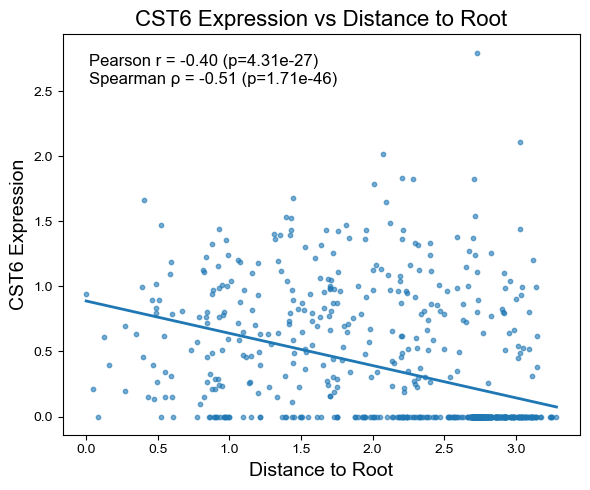

Saved plot:
  results/CST6_vs_distance_scatter.pdf


In [5]:
from scipy.stats import pearsonr, spearmanr
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# 1. Extract variables
# -------------------------

dist = adata.obs["distance_to_root"].astype(float).values

# Raw CST6 expression
cst6_raw = adata.raw[:, "CST6"].X

# Convert sparse → dense
if hasattr(cst6_raw, "toarray"):
    cst6_raw = cst6_raw.toarray().flatten()
else:
    cst6_raw = np.array(cst6_raw).flatten()

# -------------------------
# 2. Correlations
# -------------------------

# Pearson
pear_r, pear_p = pearsonr(dist, cst6_raw)

# Spearman
spear_r, spear_p = spearmanr(dist, cst6_raw)

print("Correlation between distance_to_root and CST6 expression:")
print(f"  Pearson r = {pear_r:.4f}, p = {pear_p:.4e}")
print(f"  Spearman ρ = {spear_r:.4f}, p = {spear_p:.4e}")

# -------------------------
# 3. Plot (scatter + regression)
# -------------------------

fig, ax = plt.subplots(figsize=(6, 5))

# Scatter
ax.scatter(dist, cst6_raw, s=10, alpha=0.6)

# Regression line
coef = np.polyfit(dist, cst6_raw, 1)
poly = np.poly1d(coef)
xs = np.linspace(dist.min(), dist.max(), 200)
ax.plot(xs, poly(xs), linewidth=2)

# Labels & title
ax.set_xlabel("Distance to Root", fontsize=14)
ax.set_ylabel("CST6 Expression", fontsize=14)
ax.set_title("CST6 Expression vs Distance to Root", fontsize=16)

# Annotate correlations
text = (
    f"Pearson r = {pear_r:.2f} (p={pear_p:.2e})\n"
    f"Spearman ρ = {spear_r:.2f} (p={spear_p:.2e})"
)
ax.text(0.05, 0.95, text, transform=ax.transAxes,
        fontsize=12, va='top', ha='left')

plt.tight_layout()
plt.savefig("results/CST6_vs_distance_scatter.pdf", dpi=300)
plt.show()

print("Saved plot:")
print("  results/CST6_vs_distance_scatter.pdf")
